# URBAN PULSE: 03 - Exploratory Data Analysis & 15 Core Analyst Tasks
### Citizen Complaint Intelligence & Resolution Analytics
This notebook completes all **15 Core Analyst Investigations** using statistical distributions, aggregations, visualizations, and cautious operational interpretations.

**15 Core Tasks:**
1. Total Distinct Request Volume
2. Top 10 Complaint Categories by Count
3. Agency Workload Distribution
4. Request Volume by Borough
5. Monthly Request Trend
6. Demand by Weekday and Hour
7. Distribution of Recorded Request Statuses
8. Descriptive Statistics for Valid Resolution Durations
9. Median Resolution Duration by Complaint Category
10. Median Resolution Duration by Agency
11. IQR-Based Outlier Investigation
12. Resolution-Time Skewness and Distribution
13. Geographic Complaint Concentration
14. Recorded Closure-Rate Comparison
15. High-Volume and Long-Resolution Bottleneck Categories


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# Load cleaned dataset
clean_path = "../data/cleaned_data.csv"
df = pd.read_csv(clean_path, low_memory=False)
df["created_date"] = pd.to_datetime(df["created_date"])
df["closed_date"] = pd.to_datetime(df["closed_date"])

valid_res = df[df["is_valid_resolution"] == True]
print(f"Total Dataset Records: {len(df):,}")
print(f"Valid Closed Resolution Records: {len(valid_res):,}")


Total Dataset Records: 81,115
Valid Closed Resolution Records: 63,411


### Task 1: Total Distinct Request Volume
**Question:** What is the total volume of distinct service requests handled by the 311 system?  
**Analytical Goal:** Establish the baseline size and verify uniqueness.


In [2]:
total_volume = df["unique_key"].nunique()
print(f"Total Distinct Requests: {total_volume:,}")
print(f"Earliest Request Date  : {df['created_date'].min()}")
print(f"Latest Request Date    : {df['created_date'].max()}")
print(f"Distinct Agencies      : {df['agency'].nunique()}")
print(f"Distinct Complaint Types: {df['complaint_type'].nunique()}")


Total Distinct Requests: 81,115
Earliest Request Date  : 2020-07-20 09:03:05
Latest Request Date    : 2026-11-04 21:56:50
Distinct Agencies      : 14
Distinct Complaint Types: 164


### Task 2: Top 10 Complaint Categories by Count
**Question:** What are the most frequent citizen complaint categories?  
**Analytical Goal:** Identify the primary drivers of municipal demand.


complaint_type
Illegal Parking            14828
Noise - Residential         9649
HEAT/HOT WATER              6370
Blocked Driveway            4347
Noise - Street/Sidewalk     3959
UNSANITARY CONDITION        2880
Noise - Commercial          1829
Street Condition            1533
Abandoned Vehicle           1510
PLUMBING                    1452
Name: count, dtype: int64


<ipython-input-1-4b0bdf5ed256>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


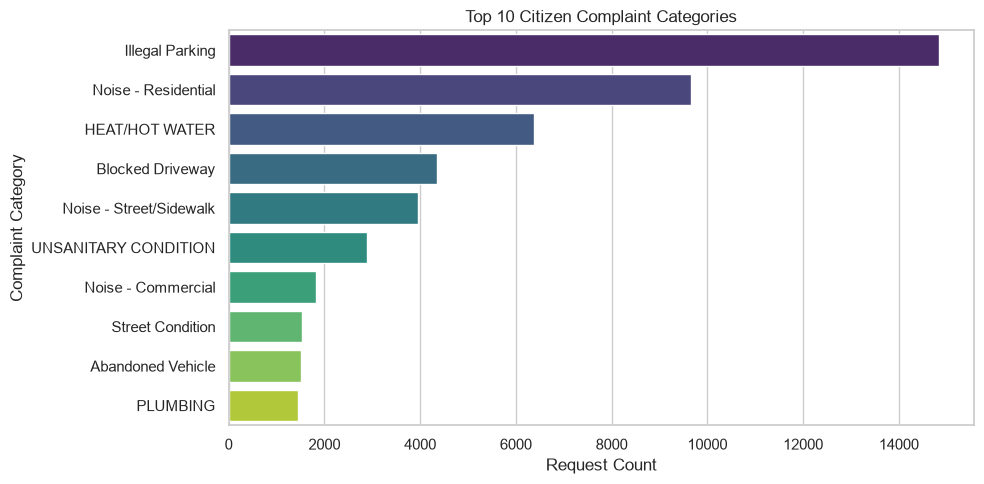

In [3]:
top10_complaints = df["complaint_type"].value_counts().head(10)
print(top10_complaints)

plt.figure(figsize=(10, 5))
sns.barplot(x=top10_complaints.values, y=top10_complaints.index, hue=top10_complaints.index, palette="viridis", legend=False)
plt.title("Top 10 Citizen Complaint Categories")
plt.xlabel("Request Count")
plt.ylabel("Complaint Category")
plt.tight_layout()
plt.show()


### Task 3: Agency Workload Distribution
**Question:** How is service request workload distributed across municipal agencies?  
**Analytical Goal:** Gauge departmental operational burden.


   Agency  Request Count  Share (%)
0    NYPD          39578      48.79
1     HPD          17470      21.54
2    DSNY           6262       7.72
3     DOT           4954       6.11
4     DEP           3743       4.61
5     DOB           2063       2.54
6     DPR           2029       2.50
7     DHS           1878       2.32
8   DOHMH           1754       2.16
9     TLC            770       0.95
10   DCWP            417       0.51
11    OOS            109       0.13
12    EDC             82       0.10
13    OTI              6       0.01


<ipython-input-1-e999b6e6d893>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


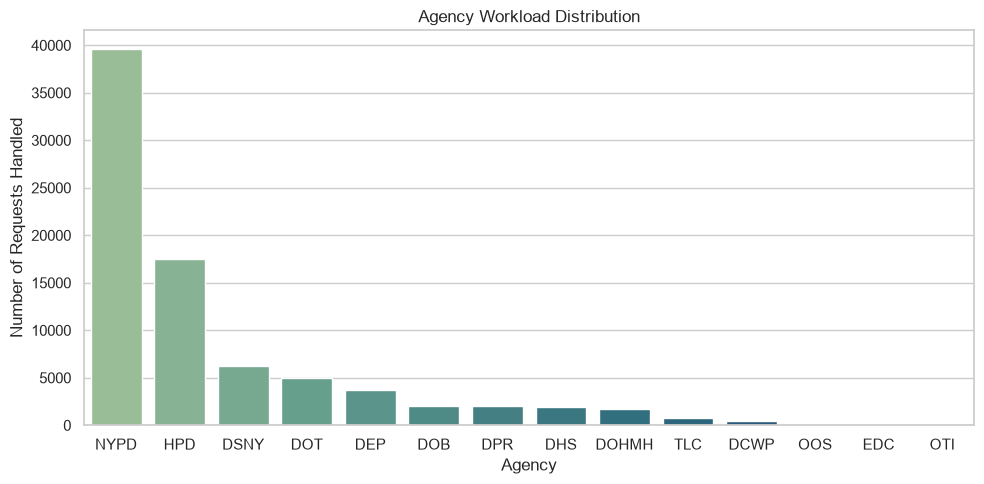

In [4]:
agency_workload = df["agency"].value_counts().reset_index()
agency_workload.columns = ["Agency", "Request Count"]
agency_workload["Share (%)"] = (agency_workload["Request Count"] / len(df) * 100).round(2)
print(agency_workload)

plt.figure(figsize=(10, 5))
sns.barplot(data=agency_workload, x="Agency", y="Request Count", hue="Agency", palette="crest", legend=False)
plt.title("Agency Workload Distribution")
plt.xlabel("Agency")
plt.ylabel("Number of Requests Handled")
plt.tight_layout()
plt.show()


### Task 4: Request Volume by Borough
**Question:** How does request volume vary across NYC's five boroughs?  
**Analytical Goal:** Identify geographic demand density.


         Borough  Request Count  Share (%)
0       BROOKLYN          26167      32.26
1         QUEENS          18946      23.36
2      MANHATTAN          18273      22.53
3          BRONX          14702      18.12
4  STATEN ISLAND           2932       3.61
5    UNSPECIFIED             95       0.12


<ipython-input-1-c4c219d6c64d>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


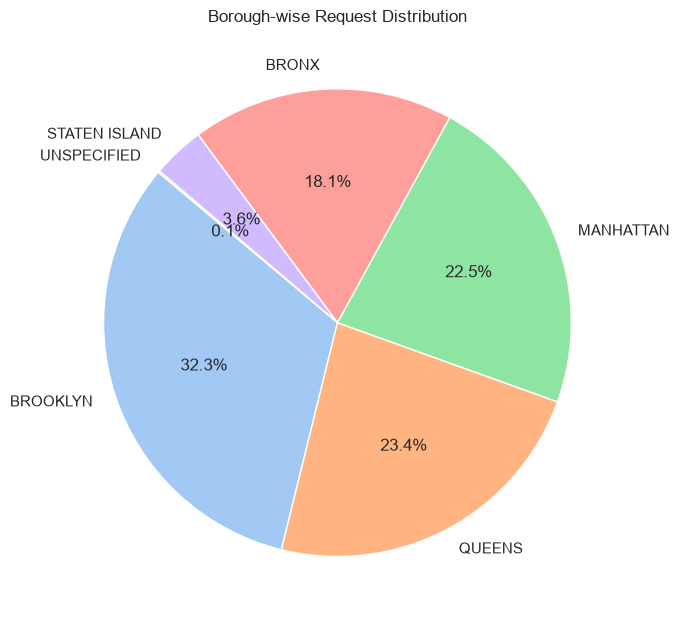

In [5]:
borough_counts = df["borough"].value_counts().reset_index()
borough_counts.columns = ["Borough", "Request Count"]
borough_counts["Share (%)"] = (borough_counts["Request Count"] / len(df) * 100).round(2)
print(borough_counts)

plt.figure(figsize=(7, 7))
plt.pie(borough_counts["Request Count"], labels=borough_counts["Borough"], autopct="%1.1f%%", startangle=140, colors=sns.color_palette("pastel"))
plt.title("Borough-wise Request Distribution")
plt.tight_layout()
plt.show()


### Task 5: Monthly Request Trend
**Question:** What is the temporal trajectory of complaint volume over time?  
**Analytical Goal:** Detect seasonal peaks to guide operational planning.


<ipython-input-1-b7f98308d675>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


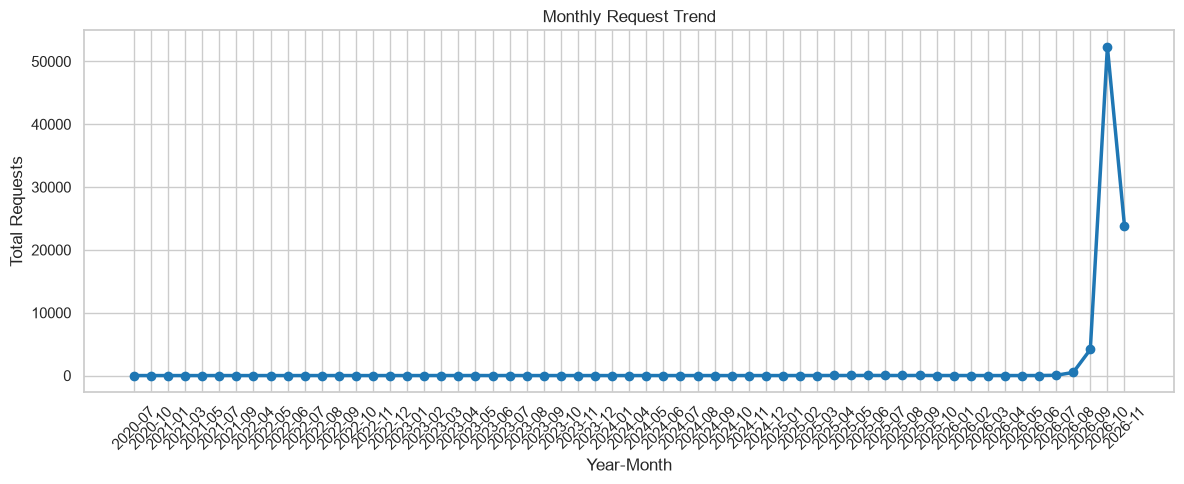

In [6]:
monthly_trend = df.groupby(["created_year", "created_month"]).size().reset_index(name="Requests")
monthly_trend["YearMonth"] = monthly_trend["created_year"].astype(str) + "-" + monthly_trend["created_month"].astype(str).str.zfill(2)

plt.figure(figsize=(12, 5))
plt.plot(monthly_trend["YearMonth"], monthly_trend["Requests"], marker="o", linewidth=2.5, color="#1f77b4")
plt.title("Monthly Request Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Task 6: Demand by Weekday and Hour
**Question:** What are the peak operating days and hours?  
**Analytical Goal:** Inform shift scheduling and staffing rotas.


<ipython-input-1-059bc1b73475>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


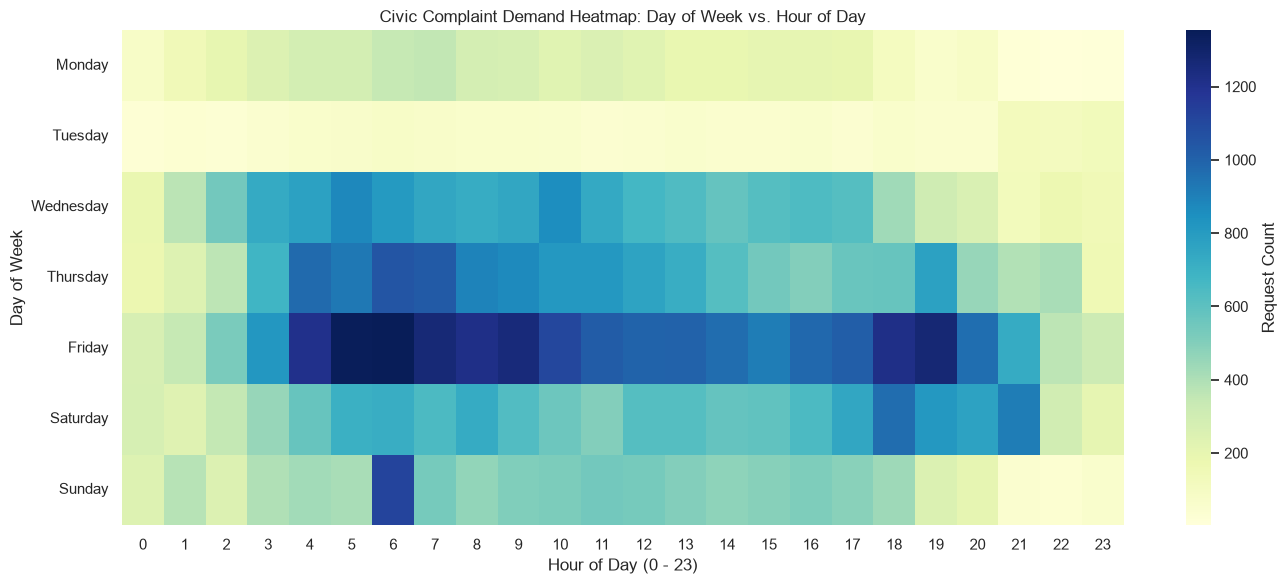

In [7]:
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heatmap_data = df.pivot_table(index="created_weekday", columns="created_hour", values="unique_key", aggfunc="count").reindex(days_order).fillna(0)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=False, fmt=".0f", cbar_kws={"label": "Request Count"})
plt.title("Civic Complaint Demand Heatmap: Day of Week vs. Hour of Day")
plt.xlabel("Hour of Day (0 - 23)")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()


### Task 7: Distribution of Recorded Request Statuses
**Question:** What proportion of requests are recorded as Closed vs Open / In Progress?  
**Analytical Goal:** Monitor ticket lifecycle state.


        Status  Count  Percentage (%)
0       Closed  61615           75.96
1         Open  10673           13.16
2  In Progress   8609           10.61
3     Assigned    198            0.24
4      Pending     17            0.02
5  Unspecified      3            0.00


<ipython-input-1-6890385db33a>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


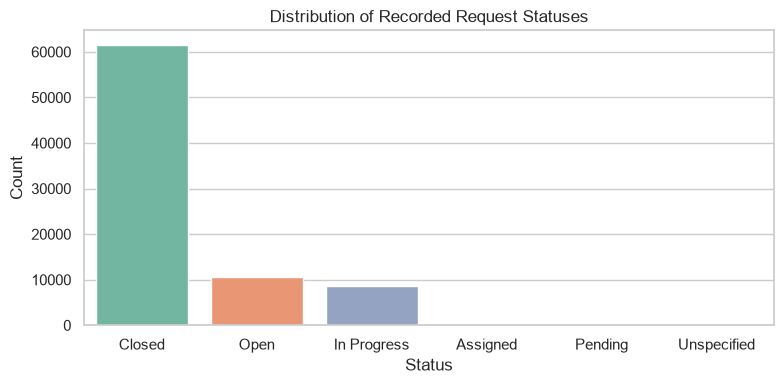

In [8]:
status_counts = df["status"].value_counts().reset_index()
status_counts.columns = ["Status", "Count"]
status_counts["Percentage (%)"] = (status_counts["Count"] / len(df) * 100).round(2)
print(status_counts)

plt.figure(figsize=(8, 4))
sns.barplot(data=status_counts, x="Status", y="Count", hue="Status", palette="Set2", legend=False)
plt.title("Distribution of Recorded Request Statuses")
plt.tight_layout()
plt.show()


### Task 8: Descriptive Statistics for Valid Resolution Durations
**Question:** What are the central tendency, spread, and extremes of resolution times?  
**Analytical Goal:** Establish rigorous baseline resolution metrics.


In [9]:
desc_stats = valid_res["resolution_hours"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
q1 = valid_res["resolution_hours"].quantile(0.25)
q3 = valid_res["resolution_hours"].quantile(0.75)
iqr = q3 - q1

print(desc_stats)
print(f"\nInterquartile Range (IQR): {iqr:.2f} hours")
print(f"Mean Resolution Hours    : {valid_res['resolution_hours'].mean():.2f}")
print(f"Median Resolution Hours  : {valid_res['resolution_hours'].median():.2f}")


count    63411.000000
mean        68.036649
std        854.600610
min          0.000000
25%          0.787500
50%          2.822778
75%         23.938056
90%         89.559722
95%        148.360278
max      52020.854444
Name: resolution_hours, dtype: float64

Interquartile Range (IQR): 23.15 hours
Mean Resolution Hours    : 68.04
Median Resolution Hours  : 2.82


### Task 9: Median Resolution Duration by Complaint Category
**Question:** Which complaint categories require the longest median time to resolve?  
**Analytical Goal:** Account for category complexity using median (robust against right skew).


                 complaint_type  count       median         mean
121              Taxi Complaint     10  6259.996806  5338.163306
51   For Hire Vehicle Complaint     11  5919.419167  5980.518788
49           Food Establishment     41  1440.200833  1372.184614
111           Smoking or Vaping     17   956.559167   832.215245
125               Unleashed Dog     13   267.845556   254.474957
30              Dead/Dying Tree     45   234.073056  9065.382272
53                      GENERAL    622   210.122778   258.892035
116      Street Light Condition    358   207.616667   568.148045
136               Water Quality     40   190.317639   278.394750
25               Curb Condition     16   182.048889   189.554253


<ipython-input-1-6e1ca2a1b3e5>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


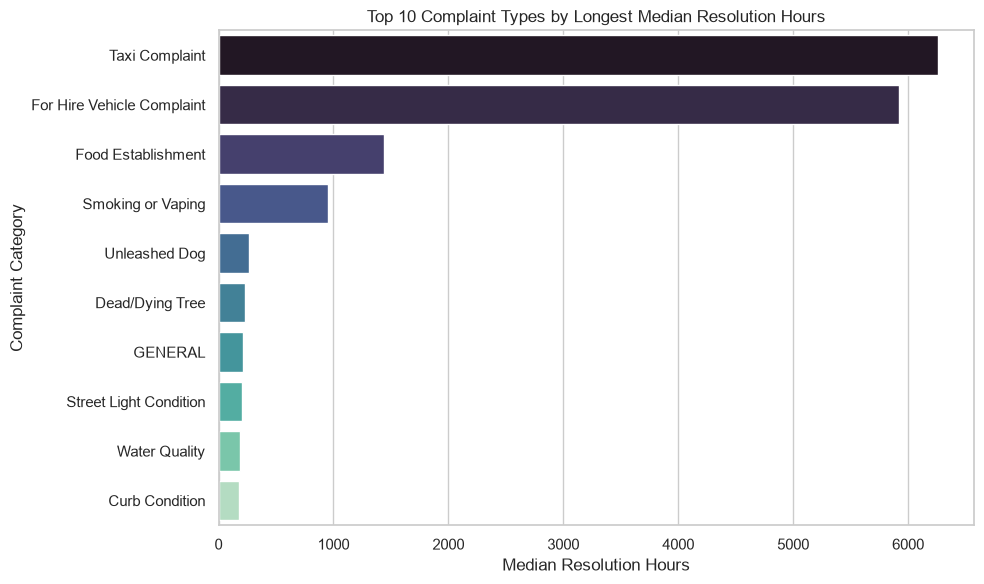

In [10]:
complaint_res = valid_res.groupby("complaint_type")["resolution_hours"].agg(["count", "median", "mean"]).reset_index()
complaint_res = complaint_res[complaint_res["count"] >= 10].sort_values(by="median", ascending=False)
print(complaint_res.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=complaint_res.head(10), y="complaint_type", x="median", hue="complaint_type", palette="mako", legend=False)
plt.title("Top 10 Complaint Types by Longest Median Resolution Hours")
plt.xlabel("Median Resolution Hours")
plt.ylabel("Complaint Category")
plt.tight_layout()
plt.show()


### Task 10: Median Resolution Duration by Agency
**Question:** How does median turnaround compare across agencies?  
**Analytical Goal:** Evaluate departmental turnaround with realistic context.


   agency  count      median         mean
11    OTI      1  289.001111   289.001111
10    OOS      9  102.774444    99.102840
4   DOHMH    467   83.203333   256.033515
12    TLC    122   68.092639  1025.922104
0    DCWP    121   64.432222   169.155689
8     HPD   9580   62.697222   110.277422
6     DPR    491   61.440000  2362.564510
7    DSNY   4678   30.408333    51.034933
5     DOT   2648   24.468611   131.032780
1     DEP   2432   22.456528   125.441298
2     DHS   1769    6.487778    10.449513
9    NYPD  39030    1.378333     3.475119
3     DOB   2063    0.000000   381.244608


<ipython-input-1-95b21080e0a7>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


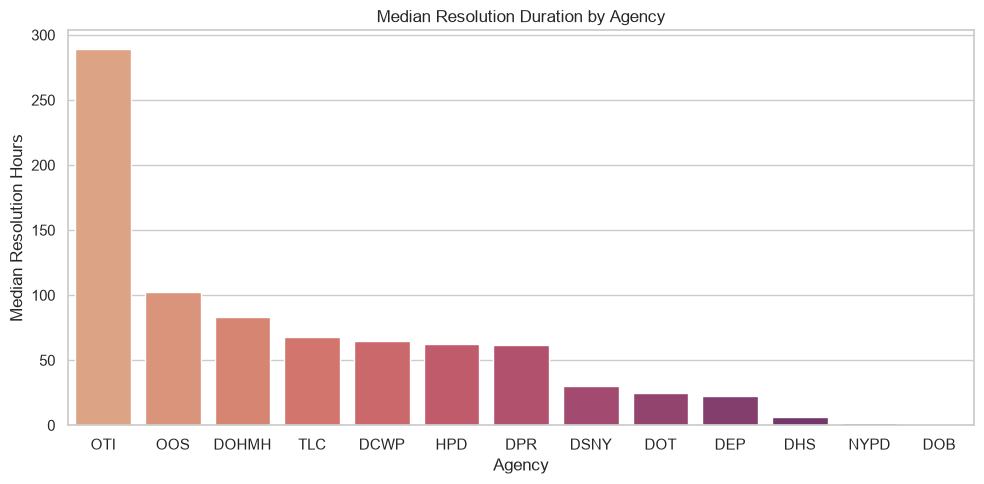

In [11]:
agency_res = valid_res.groupby("agency")["resolution_hours"].agg(["count", "median", "mean"]).reset_index()
agency_res = agency_res.sort_values(by="median", ascending=False)
print(agency_res)

plt.figure(figsize=(10, 5))
sns.barplot(data=agency_res, x="agency", y="median", hue="agency", palette="flare", legend=False)
plt.title("Median Resolution Duration by Agency")
plt.xlabel("Agency")
plt.ylabel("Median Resolution Hours")
plt.tight_layout()
plt.show()


### Task 11: IQR-Based Outlier Investigation
**Question:** How many requests exhibit extreme resolution durations?  
**Analytical Goal:** Screen long-tail service cases without blind deletion.


Q1 (25th): 0.79 hrs | Q3 (75th): 23.94 hrs | IQR: 23.15 hrs
Lower Bound: 0.00 hrs | Upper Bound: 58.66 hrs
Total Outliers: 9,458 (14.92% of valid closed cases)


<ipython-input-1-de1f04ce27b4>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


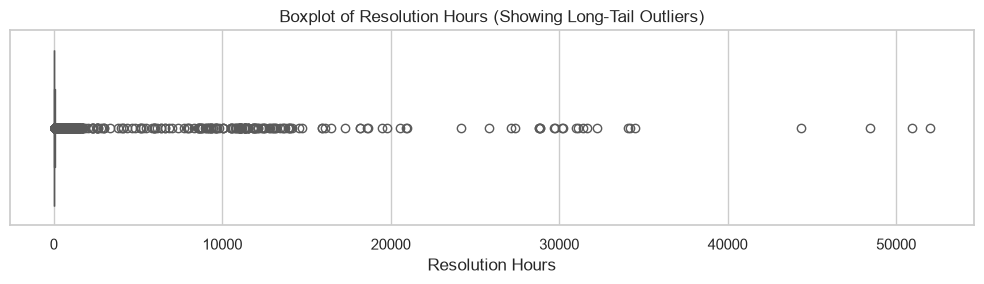

In [12]:
q1 = valid_res["resolution_hours"].quantile(0.25)
q3 = valid_res["resolution_hours"].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0.0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

outliers = valid_res[(valid_res["resolution_hours"] < lower_bound) | (valid_res["resolution_hours"] > upper_bound)]
print(f"Q1 (25th): {q1:.2f} hrs | Q3 (75th): {q3:.2f} hrs | IQR: {iqr:.2f} hrs")
print(f"Lower Bound: {lower_bound:.2f} hrs | Upper Bound: {upper_bound:.2f} hrs")
print(f"Total Outliers: {len(outliers):,} ({len(outliers)/len(valid_res)*100:.2f}% of valid closed cases)")

plt.figure(figsize=(10, 3))
sns.boxplot(x=valid_res["resolution_hours"], color="#4a90e2")
plt.title("Boxplot of Resolution Hours (Showing Long-Tail Outliers)")
plt.xlabel("Resolution Hours")
plt.tight_layout()
plt.show()


### Task 12: Resolution-Time Skewness and Distribution
**Question:** What is the distributional shape and skewness of resolution durations?  
**Analytical Goal:** Demonstrate why median is the superior central tendency measure.


Resolution Duration Skewness Coefficient: 31.732
Interpretation: Distribution is strongly right-skewed (positive tail).


<ipython-input-1-e22dec0b98d8>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


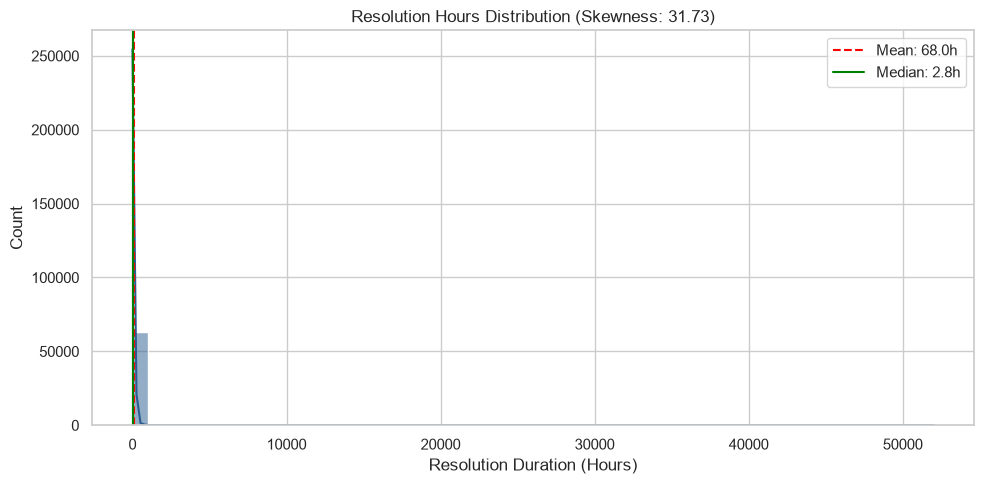

In [13]:
skew_val = valid_res["resolution_hours"].skew()
print(f"Resolution Duration Skewness Coefficient: {skew_val:.3f}")
print("Interpretation: Distribution is strongly right-skewed (positive tail).")

plt.figure(figsize=(10, 5))
sns.histplot(valid_res["resolution_hours"], bins=50, kde=True, color="#2b5c8f")
plt.axvline(valid_res["resolution_hours"].mean(), color="red", linestyle="--", label=f"Mean: {valid_res['resolution_hours'].mean():.1f}h")
plt.axvline(valid_res["resolution_hours"].median(), color="green", linestyle="-", label=f"Median: {valid_res['resolution_hours'].median():.1f}h")
plt.title(f"Resolution Hours Distribution (Skewness: {skew_val:.2f})")
plt.xlabel("Resolution Duration (Hours)")
plt.legend()
plt.tight_layout()
plt.show()


### Task 13: Geographic Complaint Concentration
**Question:** Where are complaints spatially concentrated across New York City?  
**Analytical Goal:** Identify neighborhood and corridor demand hotspots.


<ipython-input-1-3b2ead658e42>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


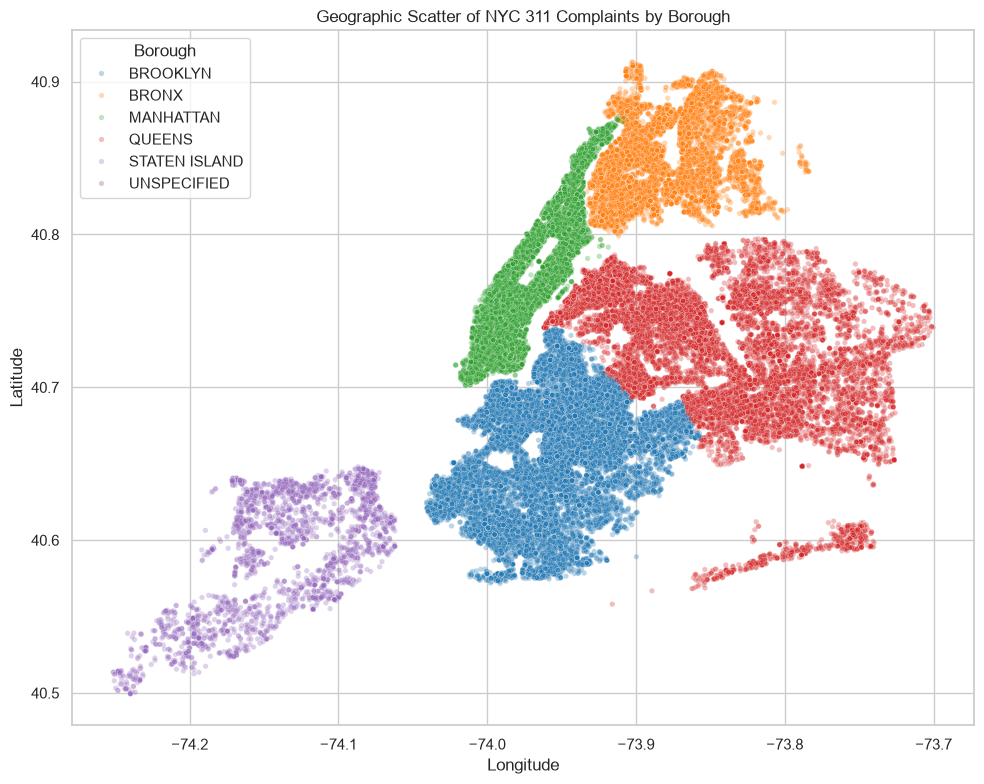

In [14]:
geo_valid = df.dropna(subset=["latitude", "longitude"])
geo_valid = geo_valid[geo_valid["latitude"].between(40.45, 41.05) & geo_valid["longitude"].between(-74.30, -73.65)]

plt.figure(figsize=(10, 8))
sns.scatterplot(data=geo_valid, x="longitude", y="latitude", hue="borough", alpha=0.3, s=15, palette="tab10")
plt.title("Geographic Scatter of NYC 311 Complaints by Borough")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Borough")
plt.tight_layout()
plt.show()


### Task 14: Recorded Closure-Rate Comparison
**Question:** How does ticket closure rate vary across agencies?  
**Analytical Goal:** Review administrative completion rates while noting closure != satisfaction.


   agency  Total_Requests  Closed_Requests  Closure_Rate_Pct
3     DOB            2063             2063            100.00
10   NYPD           39578            39056             98.68
2     DHS            1878             1769             94.20
7    DSNY            6262             4680             74.74
1     DEP            3743             2469             65.96
9     HPD           17470             9580             54.84
5     DOT            4954             2656             53.61
0    DCWP             417              121             29.02
4   DOHMH            1754              467             26.62
6     DPR            2029              491             24.20
12    OTI               6                1             16.67
13    TLC             770              122             15.84
11    OOS             109                9              8.26
8     EDC              82                0              0.00


<ipython-input-1-b10a5d2a7117>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


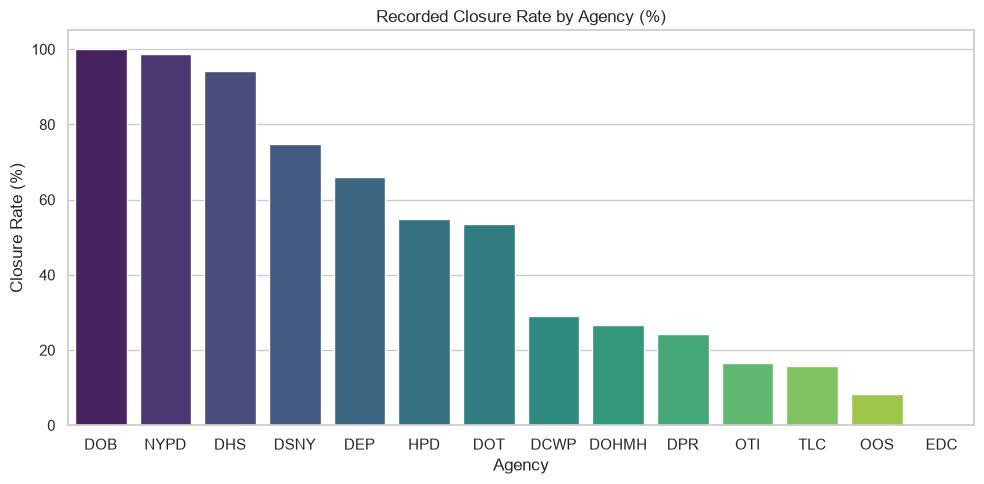

In [15]:
closure_rates = df.groupby("agency").agg(
    Total_Requests=("unique_key", "count"),
    Closed_Requests=("is_closed", "sum")
).reset_index()
closure_rates["Closure_Rate_Pct"] = (closure_rates["Closed_Requests"] / closure_rates["Total_Requests"] * 100).round(2)
closure_rates = closure_rates.sort_values(by="Closure_Rate_Pct", ascending=False)
print(closure_rates)

plt.figure(figsize=(10, 5))
sns.barplot(data=closure_rates, x="agency", y="Closure_Rate_Pct", hue="agency", palette="viridis", legend=False)
plt.title("Recorded Closure Rate by Agency (%)")
plt.xlabel("Agency")
plt.ylabel("Closure Rate (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


### Task 15: Categories with Both High Request Volume and Long Median Resolution Duration
**Question:** Which complaint categories represent critical civic bottlenecks (high volume & slow resolution)?  
**Analytical Goal:** 2x2 Quadrant Analysis to prioritize civic process improvements.


Overall Volume Benchmark: 43 requests | Duration Benchmark: 56.12 hrs
Identified Bottleneck Categories (25):
                     complaint_type  total_requests  median_res
124            UNSANITARY CONDITION             980  147.859028
84                            Noise             895   69.809167
53                          GENERAL             622  210.122778
96                    PAINT/PLASTER             553  127.258056
97                         PLUMBING             550   98.446250
116          Street Light Condition             358  207.616667
26                      DOOR/WINDOW             354  141.835278
132                      WATER LEAK             305  144.318611
40                         ELECTRIC             291   96.923333
110              Sidewalk Condition             232  118.511667
103  Residential Disposal Complaint             182   64.649028
46                  FLOORING/STAIRS             173  147.760000
1                         APPLIANCE             167  147.09

<ipython-input-1-0f1b7b7638e0>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


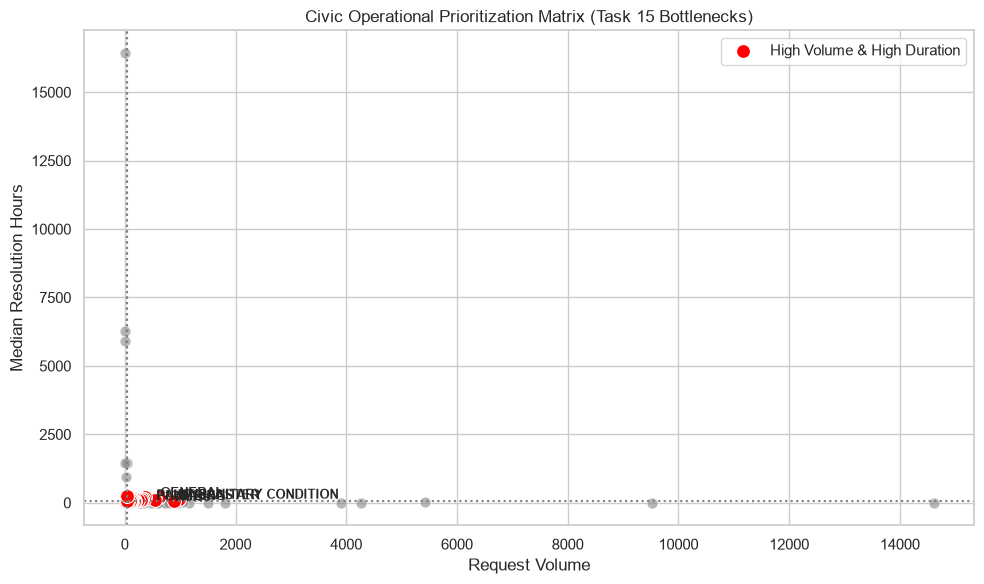

In [16]:
cat_matrix = valid_res.groupby("complaint_type").agg(
    total_requests=("unique_key", "count"),
    median_res=("resolution_hours", "median")
).reset_index()

vol_median = cat_matrix["total_requests"].median()
dur_median = cat_matrix["median_res"].median()

bottlenecks = cat_matrix[(cat_matrix["total_requests"] >= vol_median) & (cat_matrix["median_res"] >= dur_median)]
bottlenecks = bottlenecks.sort_values(by="total_requests", ascending=False)
print(f"Overall Volume Benchmark: {vol_median:.0f} requests | Duration Benchmark: {dur_median:.2f} hrs")
print(f"Identified Bottleneck Categories ({len(bottlenecks)}):")
print(bottlenecks)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=cat_matrix, x="total_requests", y="median_res", color="#888888", alpha=0.6, s=60)
sns.scatterplot(data=bottlenecks, x="total_requests", y="median_res", color="red", s=100, label="High Volume & High Duration")
plt.axvline(vol_median, color="grey", linestyle=":")
plt.axvline(vol_median, color="grey", linestyle=":")
plt.axhline(dur_median, color="grey", linestyle=":")
for _, row in bottlenecks.head(5).iterrows():
    plt.text(row["total_requests"] + 20, row["median_res"], row["complaint_type"], fontsize=9, weight="bold")
plt.title("Civic Operational Prioritization Matrix (Task 15 Bottlenecks)")
plt.xlabel("Request Volume")
plt.ylabel("Median Resolution Hours")
plt.legend()
plt.tight_layout()
plt.show()
